In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import json


# All imported in ic_visualization.py:
import requests #for url downloading
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.table import QTable
import astropy_healpix as ah
from regions import PointSkyRegion
import healpy as hp
import mhealpy as mhp
from mhealpy import HealpixMap
import ligo.skymap.plot
from ligo.skymap.io.fits import read_sky_map

sys.path.insert(1, '../../') #check where your ic_visualization.py file is, add path to it
from ic_visualization import plot_IC_alert, write_new_yaml, plot_zoomed_IC_alert, select_pixels, check_source_in_map
from params import p

import mhealpy as mh

/Users/cristozilleruelo/opt/anaconda3/envs/AMPEL/lib/python3.12/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)
print('latest alert: ')
alert = alerts[-2]
alert

latest alert: 


{'$schema': 'https://gcn.nasa.gov/schema/v6.1.1/gcn/notices/icecube/single_neutrino_alerts.schema.json',
 'mission': 'IceCube',
 'instrument': 'IC86',
 'messenger': 'Neutrino',
 'pipeline': 'Gold Track Alert',
 'record_number': 1,
 'event_name': ['IceCube-260610A'],
 'id': ['142709_10606089'],
 'alert_datetime': '2026-06-11T03:06:22.8Z',
 'alert_type': 'update',
 'alert_tense': 'current',
 'alert_topology': 'Track',
 'number_of_events': 1,
 'ra': 309.2,
 'dec': 37.22,
 'ra_dec_error': 1.24,
 'containment_probability': 0.9,
 'systematic_included': True,
 'healpix_url': 'https://roc-2.icecube.wisc.edu/public/alerts/IceCube-260610A_skymap_probdensity_multiorder.fits.gz',
 'trigger_time': '2026-06-10T20:02:41.035Z',
 'nu_energy': 887.79,
 'p_astro': 0.9214,
 'far': 4.7359e-09}

In [3]:
# def plot_IC_alert(map_name, map_dir=p['map_dir'], coord='icrs', nest=True, plot_zoom_title=True, use_hpx_max=False, save_dir=p['save_dir'], show_fig=True,
#                   print_radec_diff=False, map_from_url=True, hpx=None, header=None, use_own_hpx=False, normalize=False, title='',
#                   ra_dec_err=None, plot_50=False, plot_90=False, plot_source=None, r=3, plot_prob_density=False):
#     '''
#     Docstring for plot_IC_alert
    
#     Params:
#     --------
#     map_name: str, file name of map inside map_dir. It has to be a fits.gz file. 
#     map_dir: path to directory that contains the probability maps. It can be set when calling the funciton or in 
#         the params.py file
#     coord: srt. Coordinate system:
#         E -> Equatorial (ITRS)
#         G -> Galactic
#         icrs -> Celestial coordinates, Solar system, J2000
#     plot_zoom_title: bool. If True, then shows the ra and dec where the zoom plot is centered. 
#     use_hpx_max: bool. If True, then the center ra and dec of the zoom plot is calculated directly from the 
#         probability map. If False, ra and dec are read from the header of the alert file. 
#     save_dir: str. Path to directory where the plot should be saved. If save_dir='' or save_dir=False then the figure is not saved.
#     show_fig: bool. Determines if the figure is shown with plt.show()
#     print_radec_diff: bool. If true then both ra and dec methods of calculating are plotted, including the difference.
#     map_from_url: bool. If True, map is downloaded directly from the url . If False, then asumes map is stored localy in map_dir

#     Returns:
#     title: str, alert name
#     ra_diff, dec_diff: float. Difference in ra and dec between max pixel in healpix map and the header info. max_hpx - header 
#         in degrees. 

#     The maps need to be read with read_sky_map from ligo.skymap.io.fits, and not with healpy.read_map. Not sure why, but the healpy function
#     can raise an IndexError. 
#     '''

#     #plotting info
#     ligo_coord = {
#         'E': 'geo',
#         'icrs': 'astro',
#         'G': 'galactic'
#     }
#     astropy_frame = {
#         'icrs': 'icrs',
#         'G': 'galactic'
#     }
    
#     if not use_own_hpx:
#         #check if map_name is an url
#         if 'https' in map_name:
#             file_name = map_name.split('/')[-1]
#             title = file_name.split('_')[0]

#             #first we download the map
#             response = requests.get(map_name)
#             map_path = os.path.join(map_dir, file_name)
#             with open(map_path, 'wb') as file: #also deletes previously existing file and redownloads alert. 
#                 file.write(response.content)
            
#         else: #we get a path to the data
#             title = map_name.split('_')[0]
#             map_path = map_name
#             # data, header = fits.getdata(map_name, header=True)
#             # hpx, _ = read_sky_map(map_name, nest=nest)

#     try:
#         hpx, header = read_sky_map(map_path, nest=nest)
#     except ValueError as error:
#         #It means that the header contains COORDSYS='c', and read_sky_map checks for COORDSYS == 'C'. 
#         #we rewrite the header of the file and try again
        
#         data, header = fits.getdata(map_path, header=True)
#         if header['COORDSYS'] == 'c':
#             header['COORDSYS'] = 'C'
#             fits.writeto(map_path, data, header, overwrite=True)
#             #we try again
#             hpx, _ = read_sky_map(map_path, nest=nest)
#         else:
#             raise ValueError(error)
#     if normalize: #only for simulated alerts
#         hpx[hpx < 0] = 0
#         hpx = hpx / np.sum(hpx)
    
#     header_dict = dict(header)
#     h_ra = header_dict['RA'] * u.deg
#     h_dec = header_dict['DEC'] * u.deg

#     if use_hpx_max:
#         arg_max = np.argmax(hpx)
#         ra, dec = hp.pix2ang(header_dict['NSIDE'], arg_max, lonlat=True, nest=True)
#         ra = ra * u.deg
#         dec = dec * u.deg
#     else:
#         ra = h_ra
#         dec = h_dec

#     center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
#     fig = plt.figure(figsize=(6, 6), dpi=100)
    
#     ax = plt.axes(
#         [0.05, 0.05, 0.8, 0.9],
#         projection=f'{ligo_coord[coord]} degrees mollweide',
#         center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    
#     ax_inset = plt.axes(
#         [1.03, 0.3, 0.42, 0.42],
#         projection=f'{ligo_coord[coord]} degrees zoom',
#         center=center,
#         radius=r * u.deg)


#     if coord == 'icrs':
#         for key in ['ra', 'dec']:
#             # ax_inset.coords[key].set_ticklabel_visible(False)
#             ax_inset.coords[key].set_ticks_visible(False)
        
#     ax_inset.set_xlabel("")
#     ax_inset.set_ylabel("")
#     ax.grid()
#     ax.locator_params(nbins=10) #test!
#     ax.mark_inset_axes(ax_inset)
#     ax.connect_inset_axes(ax_inset, 'upper left')
#     ax.connect_inset_axes(ax_inset, 'lower left')
#     ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
#     ax_inset.compass(0.9, 0.1, 0.2)
#     ax_inset.grid()

    


#     skymap = QTable.read(map_path)

#     #Check if unmasked values have a NaN
#     try:
#         if skymap['PROBDENSITY'].mask.any():
#             print("Map has masked values. reeplacing them with 0")
#             skymap['PROBDENSITY'] = skymap['PROBDENSITY'].filled(0)
#     except AttributeError:
#         pass #array has no masked values
    
#     level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
#     nside = ah.level_to_nside(level)
#     # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
#     # match_index = np.flatnonzero(ipix == match_ipix)[0]
#     if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
#         skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
#     #test
#     prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)
#     # prob_density = prob_density.unmasked

#     #plot map with prob_density only
#     if plot_prob_density:
#         m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
#         img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
#         ax.imshow(img, cmap='OrRd')
#         img_inset = m.get_wcs_img(ax_inset)
#         im = ax_inset.imshow(img_inset, cmap='OrRd')
#         c = plt.colorbar(im, label=r'Prob density [$deg^{-2}$]')
#     else:
#         #we show prob_density * pixel_area
#         level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
#         nside = ah.level_to_nside(level)
#         pixel_area = ah.nside_to_pixel_area(nside)
#         # print("PIXEL AREA \n", pixel_area.to(u.deg**2))
#         prob = pixel_area * skymap['PROBDENSITY']

#         m = mhp.HealpixMap(data=prob, uniq=skymap['UNIQ'], density=False)
#         img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
#         ax.imshow(img, cmap='OrRd')
#         img_inset = m.get_wcs_img(ax_inset)
#         im = ax_inset.imshow(img_inset, cmap='OrRd')
#         c = plt.colorbar(im, label=r'Pixel Probability')

#     ax.set_title(title)

    
    
#     h_center = SkyCoord(h_ra.to('rad'), h_dec.to('rad'), frame=astropy_frame[coord])


#     #90 % region
#     # print("A: ", skymap['PROBDENSITY'].unmasked)
#     skymap.sort("PROBDENSITY", reverse=True)
#     # print("B: ", skymap['PROBDENSITY'].unmasked)
#     level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
#     nside = ah.level_to_nside(level)
#     pixel_area = ah.nside_to_pixel_area(nside)
#     prob = pixel_area * skymap["PROBDENSITY"]
#     print('TOTAL PROB: ', np.sum(prob))
#     print(f'Smallest pixel is NSIDE: {np.max(nside)} of Area {ah.nside_to_pixel_area(np.max(nside)).to(u.deg**2)}')


#     cumprob = np.cumsum(prob)
#     # print('array[0] = ', cumprob.unmasked.value[0])
#     # searchsorted gives the FIRST index where cumprob >= target.
#     i_50 = cumprob.searchsorted(0.5)
#     i_90 = cumprob.searchsorted(0.9)
    
#     m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
#     img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
#     im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,
#     # c = plt.colorbar(im, label=r'Cum prob [$deg^{-2}$]')

#     area_50 = pixel_area[:i_50].sum().to(u.deg**2)
#     area_90 = pixel_area[:i_90].sum().to(u.deg**2)

#     #area text
#     props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
#     text_str = f'Area 50%:\n {area_50:.3f} \n\nArea 90%:\n {area_90:.3f}'
#     ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')

#     #Plot LSST and ZTF observing limits
#     lsst_limit =  [np.linspace(0,360, 50), np.ones(50) * 30]
#     ztf_limit = [np.linspace(0,360, 50), np.ones(50) * -30]
#     ax.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax.get_transform('world'))
#     ax.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax.get_transform('world'))

#     ax_inset.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax_inset.get_transform('world'))
#     ax_inset.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax_inset.get_transform('world'))
    

#     ax.text(175, 20, r'$\downarrow$LSST', c='purple', transform=ax.get_transform('world'))
#     ax.text(175, -28, r'$\uparrow$ZTF', c='green', transform=ax.get_transform('world'))
    
#     #plot a candidate source
#     if plot_source:
#         if type(plot_source) == dict:
#             ax_inset.plot(plot_source['ra'],
#                         plot_source['dec'], 'o',
#                         label=plot_source['name'],
#                         c='cyan',  transform=ax_inset.get_transform('world'))    
#             ax_inset.legend(framealpha=1)
#         elif type(plot_source) ==  list:
#             for source in plot_source:
#                 ax_inset.plot(source['ra'],
#                         source['dec'], 'o',
#                         label=source['name'],
#                         transform=ax_inset.get_transform('world'))    
#                 ax_inset.legend(framealpha=1)

    
#     #plot params    
#     if plot_zoom_title:
#         ra_title = ra / u.deg
#         dec_title = dec / u.deg
#         ax_inset.set_title(fr'RA: {ra_title:.2f}$\degree$  DEC: {dec_title:.2f}$\degree$')
#     if save_dir:
#         plt.savefig(os.path.join(save_dir, f'{title}_mw_zoom.png'), bbox_inches='tight')
#     if show_fig:
#         plt.show()
    

#     return map_path, area_90, m


Map has masked values. reeplacing them with 0


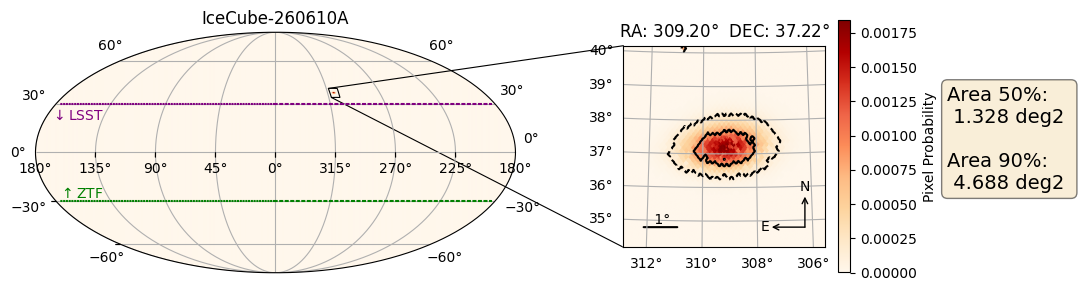

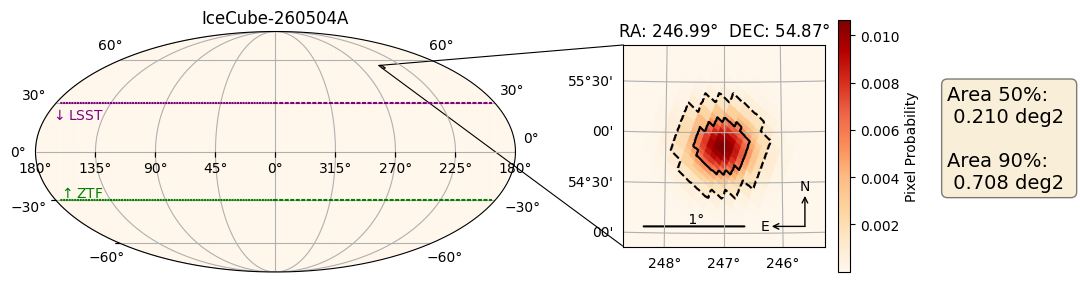

In [6]:
# map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=3, plot_prob_density=True)#
map_path, A_90, m = plot_IC_alert(alert['healpix_url'], r=3, plot_prob_density=False)#
map_path, A_90, m = plot_IC_alert(alerts[-3]['healpix_url'], r=1, plot_prob_density=False)#

In [ ]:
import astropy 
skymap = QTable.read(map_path)


# qtable['PROBDENSITY'] = qtable['PROBDENSITY'].filled(0)
# skymap['PROBDENSITY'].unmasked
skymap['PROBDENSITY'] = skymap['PROBDENSITY'].filled(0)

level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
nside = ah.level_to_nside(level)
pixel_area = ah.nside_to_pixel_area(nside)

print(skymap['PROBDENSITY'])
print(pixel_area)
print(skymap['PROBDENSITY'] * pixel_area)
print(np.sum(skymap['PROBDENSITY'] * pixel_area))

AttributeError: 'Quantity' object has no 'filled' member

In [ ]:
len(qtable)

5185

In [ ]:
def plot_figure(data, uniq, ra, dec, title='', cmap_label='', skymap=None, plot_source=None, coord='icrs', r=3,
                plot_zoom_title=None, save_dir='', show_fig=None):
    #plotting info
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }
    
    
    
    # header_dict = dict(header)
    ra = ra * u.deg
    dec = dec * u.deg

    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)
    
    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    
    ax_inset = plt.axes(
        [1.03, 0.3, 0.42, 0.42],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=r * u.deg)


    if coord == 'icrs':
        for key in ['ra', 'dec']:
            # ax_inset.coords[key].set_ticklabel_visible(False)
            ax_inset.coords[key].set_ticks_visible(False)
        
    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()

    #get map
    m = mhp.HealpixMap(data=data, uniq=uniq, density=True)
    img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
    ax.imshow(img, cmap='OrRd')
    img_inset = m.get_wcs_img(ax_inset)
    im = ax_inset.imshow(img_inset, cmap='OrRd')
    c = plt.colorbar(im, label=cmap_label)

    
    ax.set_title(title)

    
    
    # h_center = SkyCoord(h_ra.to('rad'), h_dec.to('rad'), frame=astropy_frame[coord])


    #90 % region
    
    skymap.sort("PROBDENSITY", reverse=True)
    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    prob = pixel_area * skymap["PROBDENSITY"]
    # prob = prob.unmasked
    print('pROB: ', prob)


    cumprob = np.cumsum(prob)
    # print('array = ', cumprob)
    # print('array[0] = ', cumprob.unmasked.value[0])
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,
    # c = plt.colorbar(im, label=r'Cum prob [$deg^{-2}$]')

    area_50 = pixel_area[:i_50].sum().to(u.deg**2)
    area_90 = pixel_area[:i_90].sum().to(u.deg**2)

    #area text
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    text_str = f'Area 50%:\n {area_50:.3f} \n\nArea 90%:\n {area_90:.3f}'
    ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')

    #Plot LSST and ZTF observing limits
    lsst_limit =  [np.linspace(0,360, 50), np.ones(50) * 30]
    ztf_limit = [np.linspace(0,360, 50), np.ones(50) * -30]
    ax.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax.get_transform('world'))
    ax.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax.get_transform('world'))

    ax_inset.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax_inset.get_transform('world'))
    ax_inset.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax_inset.get_transform('world'))
    

    ax.text(175, 20, r'$\downarrow$LSST', c='purple', transform=ax.get_transform('world'))
    ax.text(175, -28, r'$\uparrow$ZTF', c='green', transform=ax.get_transform('world'))
    
    #plot a candidate source
    if plot_source:
        if type(plot_source) == dict:
            ax_inset.plot(plot_source['ra'],
                        plot_source['dec'], 'o',
                        label=plot_source['name'],
                        c='cyan',  transform=ax_inset.get_transform('world'))    
            ax_inset.legend(framealpha=1)
        elif type(plot_source) ==  list:
            for source in plot_source:
                ax_inset.plot(source['ra'],
                        source['dec'], 'o',
                        label=source['name'],
                        transform=ax_inset.get_transform('world'))    
                ax_inset.legend(framealpha=1)

    
    #plot params    
    if plot_zoom_title:
        ra_title = ra / u.deg
        dec_title = dec / u.deg
        ax_inset.set_title(fr'RA: {ra_title:.2f}$\degree$  DEC: {dec_title:.2f}$\degree$')
    if save_dir:
        plt.savefig(os.path.join(save_dir, f'{title}_mw_zoom.png'), bbox_inches='tight')
    if show_fig:
        plt.show()
    

    return map_path, area_90, m

In [ ]:
def debug(map_name, map_dir=p['map_dir'], coord='icrs', nest=True, plot_zoom_title=True, use_hpx_max=False, save_dir=p['save_dir'], show_fig=True,
                  print_radec_diff=False, map_from_url=True, hpx=None, header=None, use_own_hpx=False, normalize=False, title='',
                  ra_dec_err=None, plot_50=False, plot_90=False, plot_source=None, r=3, plot_prob_density=False):
    '''
    Docstring for plot_IC_alert
    
    Params:
    --------
    map_name: str, file name of map inside map_dir. It has to be a fits.gz file. 
    map_dir: path to directory that contains the probability maps. It can be set when calling the funciton or in 
        the params.py file
    coord: srt. Coordinate system:
        E -> Equatorial (ITRS)
        G -> Galactic
        icrs -> Celestial coordinates, Solar system, J2000
    plot_zoom_title: bool. If True, then shows the ra and dec where the zoom plot is centered. 
    use_hpx_max: bool. If True, then the center ra and dec of the zoom plot is calculated directly from the 
        probability map. If False, ra and dec are read from the header of the alert file. 
    save_dir: str. Path to directory where the plot should be saved. If save_dir='' or save_dir=False then the figure is not saved.
    show_fig: bool. Determines if the figure is shown with plt.show()
    print_radec_diff: bool. If true then both ra and dec methods of calculating are plotted, including the difference.
    map_from_url: bool. If True, map is downloaded directly from the url . If False, then asumes map is stored localy in map_dir

    Returns:
    title: str, alert name
    ra_diff, dec_diff: float. Difference in ra and dec between max pixel in healpix map and the header info. max_hpx - header 
        in degrees. 

    The maps need to be read with read_sky_map from ligo.skymap.io.fits, and not with healpy.read_map. Not sure why, but the healpy function
    can raise an IndexError. 
    '''

    #plotting info
    ligo_coord = {
        'E': 'geo',
        'icrs': 'astro',
        'G': 'galactic'
    }
    astropy_frame = {
        'icrs': 'icrs',
        'G': 'galactic'
    }
    
    if not use_own_hpx:
        #check if map_name is an url
        if 'https' in map_name:
            file_name = map_name.split('/')[-1]
            title = file_name.split('_')[0]

            #first we download the map
            response = requests.get(map_name)
            map_path = os.path.join(map_dir, file_name)
            with open(map_path, 'wb') as file: #also deletes previously existing file and redownloads alert. 
                file.write(response.content)
            
        else: #we get a path to the data
            title = map_name.split('_')[0]
            map_path = map_name
            # data, header = fits.getdata(map_name, header=True)
            # hpx, _ = read_sky_map(map_name, nest=nest)

    try:
        hpx, header = read_sky_map(map_path, nest=nest)
    except ValueError as error:
        #It means that the header contains COORDSYS='c', and read_sky_map checks for COORDSYS == 'C'. 
        #we rewrite the header of the file and try again
        
        data, header = fits.getdata(map_path, header=True)
        if header['COORDSYS'] == 'c':
            header['COORDSYS'] = 'C'
            fits.writeto(map_path, data, header, overwrite=True)
            #we try again
            hpx, _ = read_sky_map(map_path, nest=nest)
        else:
            raise ValueError(error)
    if normalize: #only for simulated alerts
        hpx[hpx < 0] = 0
        hpx = hpx / np.sum(hpx)
    
    header_dict = dict(header)
    h_ra = header_dict['RA'] * u.deg
    h_dec = header_dict['DEC'] * u.deg

    if use_hpx_max:
        arg_max = np.argmax(hpx)
        ra, dec = hp.pix2ang(header_dict['NSIDE'], arg_max, lonlat=True, nest=True)
        ra = ra * u.deg
        dec = dec * u.deg
    else:
        ra = h_ra
        dec = h_dec

    center = SkyCoord(ra.to('rad'), dec.to('rad'), frame=astropy_frame[coord])
    
    fig = plt.figure(figsize=(6, 6), dpi=100)
    
    ax = plt.axes(
        [0.05, 0.05, 0.8, 0.9],
        projection=f'{ligo_coord[coord]} degrees mollweide',
        center=SkyCoord(0 * u.rad, 0 * u.rad, frame=astropy_frame[coord]))
    
    ax_inset = plt.axes(
        [1.03, 0.3, 0.42, 0.42],
        projection=f'{ligo_coord[coord]} degrees zoom',
        center=center,
        radius=r * u.deg)


    if coord == 'icrs':
        for key in ['ra', 'dec']:
            # ax_inset.coords[key].set_ticklabel_visible(False)
            ax_inset.coords[key].set_ticks_visible(False)
        
    ax_inset.set_xlabel("")
    ax_inset.set_ylabel("")
    ax.grid()
    ax.locator_params(nbins=10) #test!
    ax.mark_inset_axes(ax_inset)
    ax.connect_inset_axes(ax_inset, 'upper left')
    ax.connect_inset_axes(ax_inset, 'lower left')
    ax_inset.scalebar((0.1, 0.1), 1 * u.deg).label()
    ax_inset.compass(0.9, 0.1, 0.2)
    ax_inset.grid()

    


    skymap = QTable.read(map_path)
    #Check if array has masked values. We fill them with 0.0
    try:
        if skymap['PROBDENSITY'].mask.any():
            print("Map has masked values. reeplacing them with 0")
            skymap['PROBDENSITY'] = skymap['PROBDENSITY'].filled(0)
    except AttributeError:
        pass #array has no masked values
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
        skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    #plot map with prob_density only
    if plot_prob_density:
        m = mhp.HealpixMap(data=prob_density, uniq=skymap['UNIQ'], density=True)
        img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
        ax.imshow(img, cmap='OrRd')
        img_inset = m.get_wcs_img(ax_inset)
        im = ax_inset.imshow(img_inset, cmap='OrRd')
        c = plt.colorbar(im, label=r'Prob density [$deg^{-2}$]')
    else:
        #we show prob_density * pixel_area
        level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
        nside = ah.level_to_nside(level)
        pixel_area = ah.nside_to_pixel_area(nside)
        print("PIXEL AREA \n", pixel_area.to(u.deg**2))
        prob = pixel_area.to(u.deg**2) * skymap["PROBDENSITY"]

        m = mhp.HealpixMap(data=prob, uniq=skymap['UNIQ'], density=True)
        img = m.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)
        ax.imshow(img, cmap='OrRd')
        img_inset = m.get_wcs_img(ax_inset)
        im = ax_inset.imshow(img_inset, cmap='OrRd')
        c = plt.colorbar(im, label=r'Pixel Probability')

    ax.set_title(title)

    
    
    h_center = SkyCoord(h_ra.to('rad'), h_dec.to('rad'), frame=astropy_frame[coord])


    #90 % region
    skymap.sort("PROBDENSITY", reverse=True)
    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    prob = pixel_area * skymap["PROBDENSITY"]
    # prob = prob.unmasked
    # print('pROB: ', prob)


    cumprob = np.cumsum(prob)
    # print('array = ', cumprob)
    # print('array[0] = ', cumprob.unmasked.value[0])
    # searchsorted gives the FIRST index where cumprob >= target.
    i_50 = cumprob.searchsorted(0.5)
    i_90 = cumprob.searchsorted(0.9)
    
    m_prob = mhp.HealpixMap(data=cumprob, uniq=skymap['UNIQ'], density=True)
    img = m_prob.get_wcs_img(ax_inset)#, coord = coord, rasterize = rasterize)
    im = ax_inset.contour(img, levels=[0.5, 0.9], colors=['black', 'black'], linestyles=['solid', 'dashed']) #nested=True,
    # c = plt.colorbar(im, label=r'Cum prob [$deg^{-2}$]')

    area_50 = pixel_area[:i_50].sum().to(u.deg**2)
    area_90 = pixel_area[:i_90].sum().to(u.deg**2)

    #area text
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    text_str = f'Area 50%:\n {area_50:.3f} \n\nArea 90%:\n {area_90:.3f}'
    ax.text(1.9, 0.35, text_str, fontsize=14, bbox=props, transform=ax.transAxes)#, horizontalalignment='right', va='top')

    #Plot LSST and ZTF observing limits
    lsst_limit =  [np.linspace(0,360, 50), np.ones(50) * 30]
    ztf_limit = [np.linspace(0,360, 50), np.ones(50) * -30]
    ax.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax.get_transform('world'))
    ax.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax.get_transform('world'))

    ax_inset.plot(lsst_limit[0], lsst_limit[1], c='purple', linestyle='dotted', transform=ax_inset.get_transform('world'))
    ax_inset.plot(ztf_limit[0], ztf_limit[1], c='green', linestyle='dotted', transform=ax_inset.get_transform('world'))
    

    ax.text(175, 20, r'$\downarrow$LSST', c='purple', transform=ax.get_transform('world'))
    ax.text(175, -28, r'$\uparrow$ZTF', c='green', transform=ax.get_transform('world'))
    
    #plot a candidate source
    if plot_source:
        if type(plot_source) == dict:
            ax_inset.plot(plot_source['ra'],
                        plot_source['dec'], 'o',
                        label=plot_source['name'],
                        c='cyan',  transform=ax_inset.get_transform('world'))    
            ax_inset.legend(framealpha=1)
        elif type(plot_source) ==  list:
            for source in plot_source:
                ax_inset.plot(source['ra'],
                        source['dec'], 'o',
                        label=source['name'],
                        transform=ax_inset.get_transform('world'))    
                ax_inset.legend(framealpha=1)

    
    #plot params    
    if plot_zoom_title:
        ra_title = ra / u.deg
        dec_title = dec / u.deg
        ax_inset.set_title(fr'RA: {ra_title:.2f}$\degree$  DEC: {dec_title:.2f}$\degree$')
    if save_dir:
        plt.savefig(os.path.join(save_dir, f'{title}_mw_zoom.png'), bbox_inches='tight')
    if show_fig:
        plt.show()
    

    # DEBUG
    print("Now wee plot")

    skymap = QTable.read(map_path)
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
        skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)

    plot_figure(level, skymap['UNIQ'], ra.value, dec.value, title='Level', cmap_label='Pixel level [sr]', skymap=skymap, plot_source=None, coord=coord,
                r=r)
    skymap = QTable.read(map_path)
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
        skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    plot_figure(nside, skymap['UNIQ'], ra.value, dec.value, title='NSIDE', cmap_label='Pixel nside', skymap=skymap, plot_source=None, coord=coord,
                r=r)
    skymap = QTable.read(map_path)
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
        skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    plot_figure(pixel_area, skymap['UNIQ'], ra.value, dec.value, title='Pixel Area', cmap_label='Pixel Area [sr]', skymap=skymap, plot_source=None, coord=coord,
                r=r)
    
    skymap = QTable.read(map_path)
    level, ipix = ah.uniq_to_level_ipix(skymap['UNIQ'])
    nside = ah.level_to_nside(level)
    # match_ipix = ah.lonlat_to_healpix(ra, dec, nside, order='nested') #for prob at a specific location
    # match_index = np.flatnonzero(ipix == match_ipix)[0]
    if normalize and skymap['PROBDENSITY'].unit is None: #just for simulated maps
        skymap['PROBDENSITY'] = skymap['PROBDENSITY'] / u.sr #simulated maps are missing units
    prob_density = skymap['PROBDENSITY'].to_value(u.deg**-2)

    level, ipix = ah.uniq_to_level_ipix(skymap["UNIQ"])
    nside = ah.level_to_nside(level)
    pixel_area = ah.nside_to_pixel_area(nside)
    plot_figure(pixel_area.to(u.deg ** 2), skymap['UNIQ'], ra.value, dec.value, title='Pixel Area', cmap_label='Pixel Area [deg^2]', skymap=skymap, plot_source=None, coord=coord,
                r=r)
    

    
    
    return map_path, area_90, m

Map has masked values. reeplacing them with 0


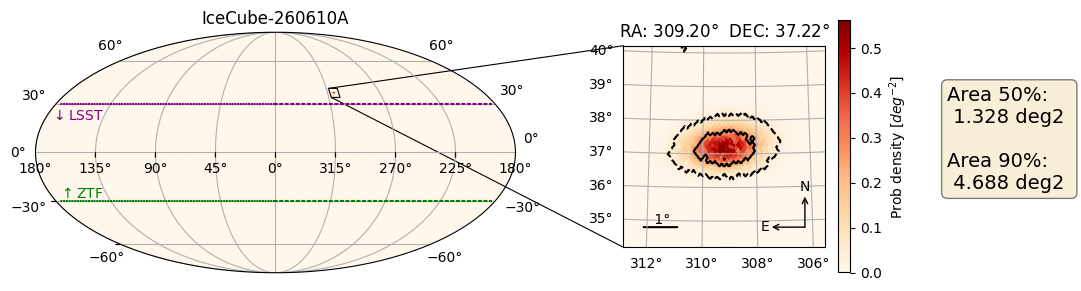

Now wee plot
pROB:  [       ———        ——— 0.00184016 ... 0.         0.         0.        ]
pROB:  [       ———        ——— 0.00184016 ... 0.         0.         0.        ]
pROB:  [       ———        ——— 0.00184016 ... 0.         0.         0.        ]
pROB:  [       ———        ——— 0.00184016 ... 0.         0.         0.        ]


('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/ic_alerts/IceCube-260610A_skymap_probdensity_multiorder.fits.gz',
 <Quantity 4.68824185 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x11fca0260>)

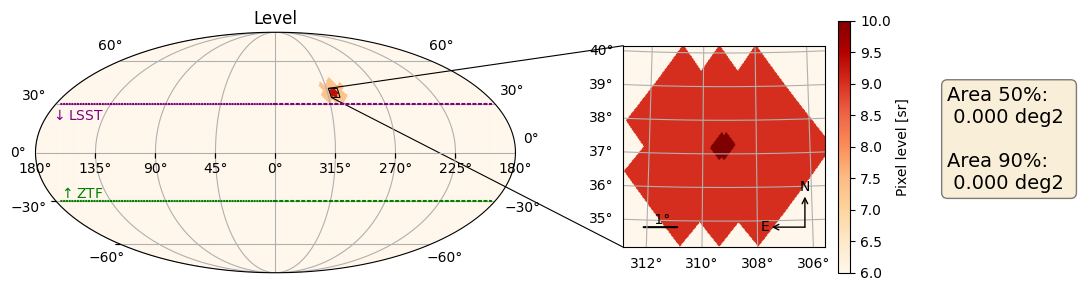

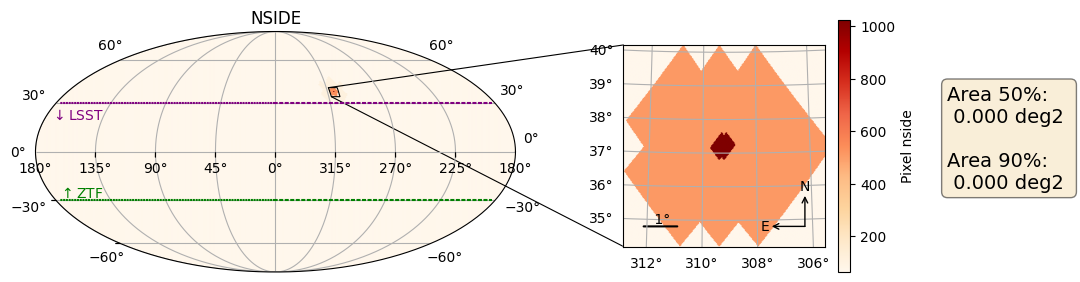

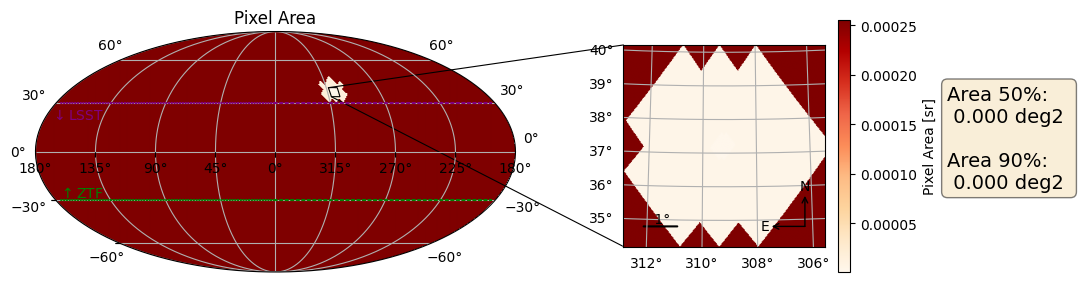

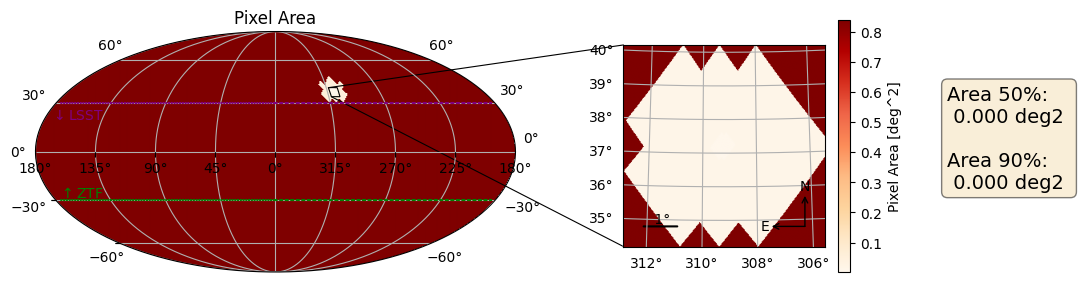

In [ ]:
debug(alerts[-2]['healpix_url'], plot_prob_density=True)